In [41]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [42]:
dataset_url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "example_images/flower_photos.tgz"
)

In [43]:
download_path = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=dataset_url,
    extract=True,
    cache_dir=None
)

base_dir = os.path.dirname(download_path)

expected_classes = {
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
}

In [44]:
data_dir = None

for root, dirs, files in os.walk(base_dir):
    if expected_classes.issubset(set(dirs)):
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError(
        "Could not find all five flower class folders. "
        "Check the dataset download and extracted files."
    )

print("Dataset directory:", data_dir)
print("Flower categories:", sorted(expected_classes))

Dataset directory: /root/.keras/datasets/flower_photos_extracted/flower_photos
Flower categories: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [45]:
for class_name in sorted(expected_classes):
    class_path = os.path.join(data_dir, class_name)
    image_count = sum(
        1 for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    print(f"{class_name}: {image_count} images")

daisy: 633 images
dandelion: 898 images
roses: 641 images
sunflowers: 699 images
tulips: 799 images


In [46]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

In [47]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [48]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [49]:
class_names = train_ds.class_names
num_classes = len(class_names)

print("\nClasses:", class_names)
print("Number of classes:", num_classes)

assert num_classes == 5, (
    f"Expected 5 classes but found {num_classes}"
)


Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of classes: 5


In [50]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(
    1000, seed=SEED
).prefetch(AUTOTUNE)

val_ds = val_ds.prefetch(AUTOTUNE)

print("Dataset loaded and split successfully.")

Dataset loaded and split successfully.


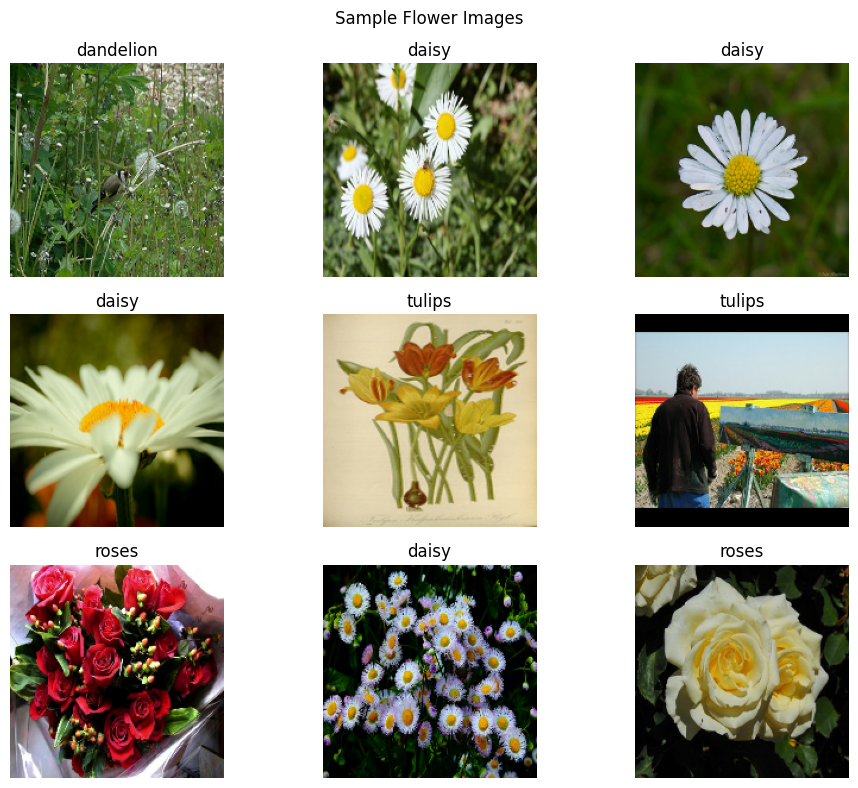

In [51]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(
            tf.cast(images[i], tf.uint8).numpy()
        )

        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.suptitle("Sample Flower Images")
plt.tight_layout()
plt.show()

In [52]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),

    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        num_classes, activation="softmax"
    )
])

model.summary()

assert model.output_shape[-1] == 5, (
    "The model must have five output neurons."
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [40]:
EPOCHS = 15

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.7176 - loss: 0.7398 - val_accuracy: 0.6812 - val_loss: 0.8440
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.7674 - loss: 0.6189 - val_accuracy: 0.6853 - val_loss: 0.8763
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.8195 - loss: 0.4781 - val_accuracy: 0.6921 - val_loss: 0.9316
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - accuracy: 0.8617 - loss: 0.3872 - val_accuracy: 0.6921 - val_loss: 0.9057
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.8934 - loss: 0.2971 - val_accuracy: 0.7016 - val_loss: 1.0289


In [ ]:
val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print(f"\nValidation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 371ms/step - accuracy: 0.6866 - loss: 0.8279

Validation Loss: 0.8279
Validation Accuracy: 68.66%



Classification Report:

              precision    recall  f1-score   support

       daisy       0.62      0.66      0.64       107
   dandelion       0.72      0.75      0.73       191
       roses       0.70      0.42      0.53       119
  sunflowers       0.75      0.79      0.77       135
      tulips       0.64      0.73      0.68       182

    accuracy                           0.69       734
   macro avg       0.69      0.67      0.67       734
weighted avg       0.69      0.69      0.68       734



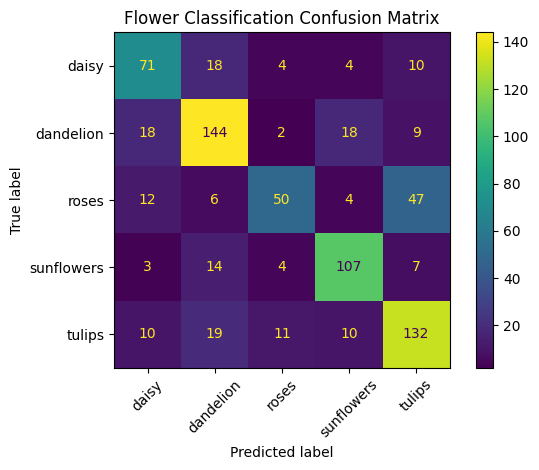

In [ ]:
y_true = []
y_pred = []

In [ ]:
for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0)

    predictions = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    )
)

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45)
plt.title("Flower Classification Confusion Matrix")
plt.tight_layout()
plt.show()

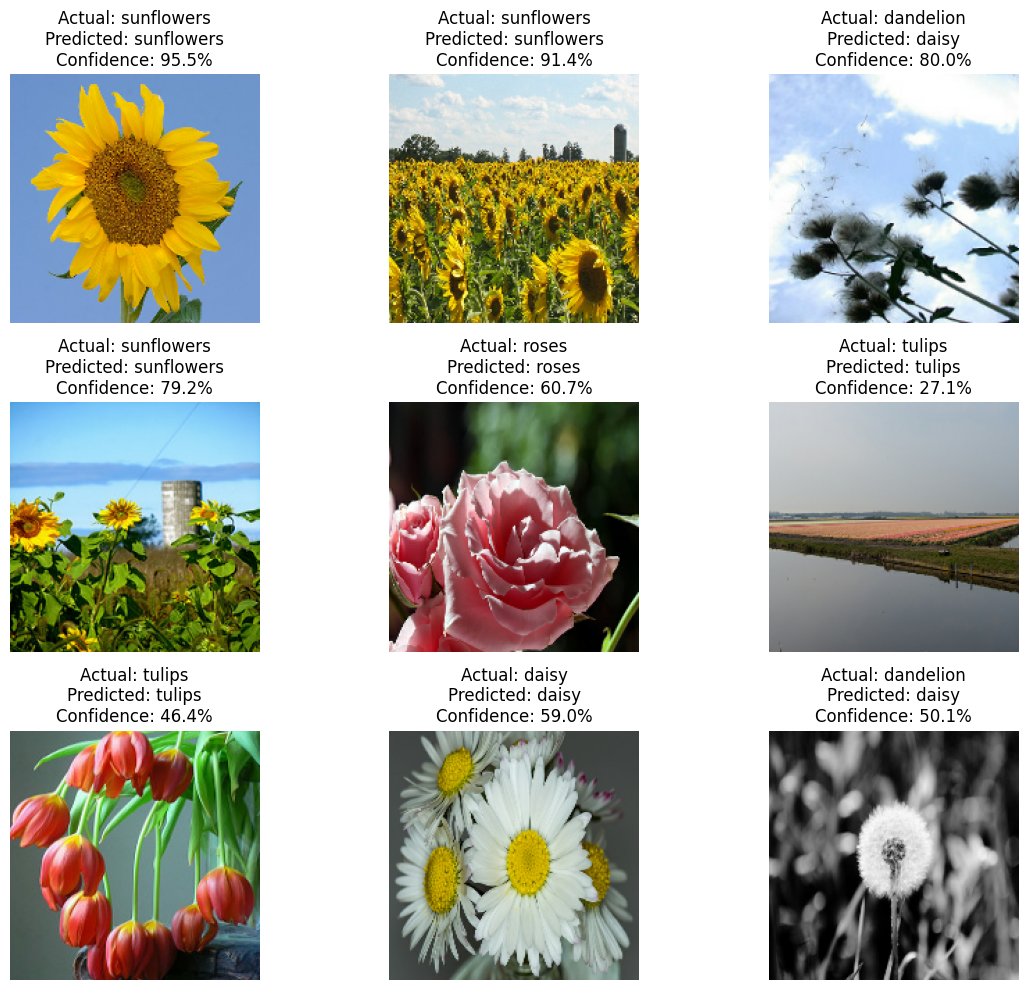

In [ ]:
plt.figure(figsize=(12, 10))

for images, labels in val_ds.take(1):
    probabilities = model.predict(images, verbose=0)

    for i in range(min(9, len(images))):
        predicted_idx = int(np.argmax(probabilities[i]))
        actual_idx = int(labels[i].numpy())

        confidence = float(probabilities[i][predicted_idx]) * 100

        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())

        plt.title(
            f"Actual: {class_names[actual_idx]}\n"
            f"Predicted: {class_names[predicted_idx]}\n"
            f"Confidence: {confidence:.1f}%"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

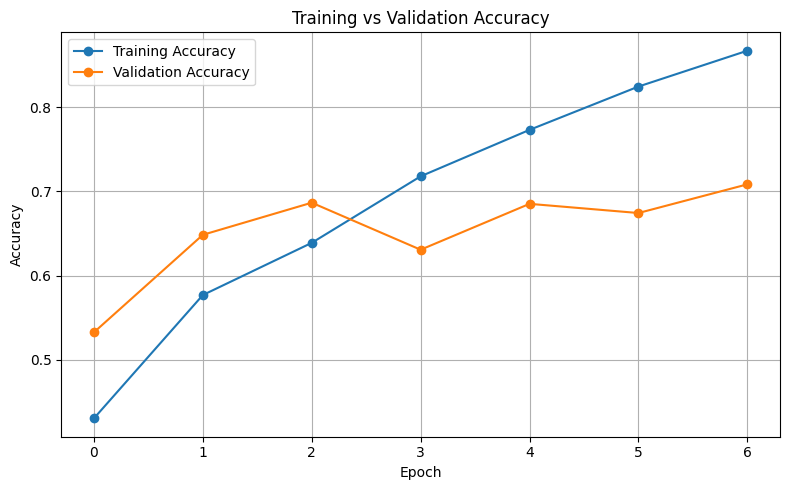

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

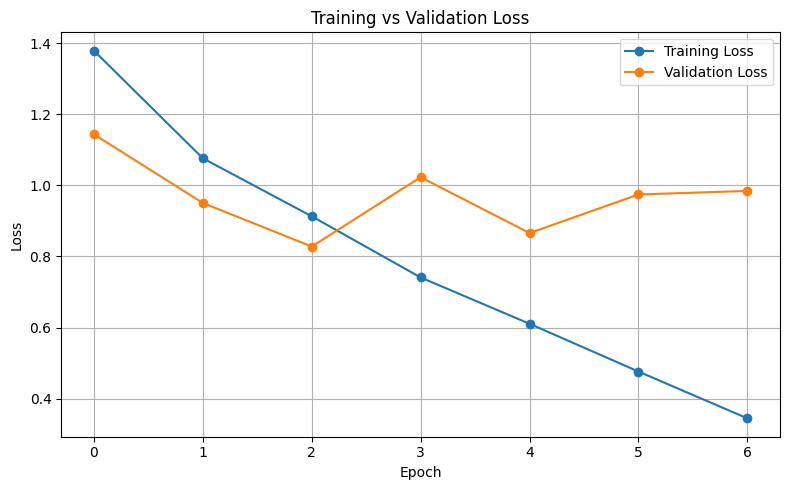

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [59]:
model.save("flower_classification_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


### Results and Discussion

A Convolutional Neural Network (CNN) was developed using TensorFlow and Keras to classify flower images into five categories: daisy, dandelion, roses, sunflowers, and tulips.

The images were resized to 180 × 180 pixels and normalized to the range 0–1. The dataset was split into 80% training data and 20% validation data. The CNN used convolutional layers with ReLU activation, max-pooling layers, a flattening layer, fully connected layers, and dropout.

The model was compiled using the Adam optimizer, sparse categorical cross-entropy loss, and accuracy as an evaluation metric. Performance was assessed using validation accuracy, validation loss, precision, recall, F1-score, a confusion matrix, and training and validation curves.

**Observed results:** Record the actual validation accuracy and loss, along with the classification report generated by the notebook.

**Possible improvements:** Data augmentation, hyperparameter tuning, batch normalization, and transfer learning with pretrained models such as MobileNetV2 could be explored to improve classification performance and generalization.